# Bài 9 · Hugging Face, tokenizer subword và mô hình tiền huấn luyện

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 8 · **Cần Internet** để tải mô hình (~0,6 GB lần đầu) · GPU không bắt buộc

## Mục tiêu

1. Hiểu hệ sinh thái Hugging Face (Hub, `transformers`, `datasets`, `tokenizers`) và cách **đọc giấy phép/thẻ mô hình** trước khi dùng.
2. Hiểu pipeline tokenizer: chuẩn hóa → tiền tách → mô hình subword → token đặc biệt; tự cài **BPE** từ đầu.
3. So sánh tokenizer của **PhoBERT, XLM-R, mBERT, Qwen** trên tiếng Việt: chi phí token, ảnh hưởng của dấu.
4. Dùng `AutoTokenizer`/`AutoModel`; hiểu `input_ids`, `attention_mask`, `last_hidden_state`.
5. Thấy tận mắt **embedding theo ngữ cảnh** giải quyết hạn chế của Bài 5 (một từ nhiều nghĩa).
6. Nhìn "đằng sau pipeline": tự làm lại `fill-mask` trong vài dòng.

> Bài này tương ứng **Chương 2 và Chương 6** của [khóa Hugging Face (bản tiếng Việt)](https://huggingface.co/docs/course/vi/chapter2/1). Hãy đọc song song: khóa đó giải thích API chi tiết, còn bài này tập trung vào những gì đặc thù với tiếng Việt.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import transformers
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM
transformers.logging.set_verbosity_error()

from nlpvi import load_splits, normalize, segment, strip_accents, tokenize_surface, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits()
print("transformers", transformers.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.is_available())

transformers 5.17.0 | torch 2.14.0+cu126 | GPU: True


## 1. Hệ sinh thái Hugging Face và giấy phép

- **Hub** (huggingface.co): kho hàng triệu mô hình, bộ dữ liệu, demo; mỗi mô hình có *thẻ mô hình* (model card) ghi dữ liệu huấn luyện, giấy phép, giới hạn.
- **`transformers`**: tải và chạy mô hình (`AutoTokenizer`, `AutoModel`, `pipeline`...).
- **`datasets`**: nạp/xử lý dữ liệu lớn. **`tokenizers`**: tokenizer nhanh viết bằng Rust.

**Trước khi dùng mô hình bất kỳ, kiểm tra giấy phép.** Cùng một "họ" mô hình có thể mang giấy phép rất khác nhau. Ta hỏi thẳng Hub:

In [2]:
from huggingface_hub import HfApi

api = HfApi()
ung_vien = ["vinai/phobert-base", "vinai/phobert-base-v2", "xlm-roberta-base",
            "intfloat/multilingual-e5-small", "Qwen/Qwen2.5-0.5B-Instruct"]
rows = []
for m in ung_vien:
    try:
        info = api.model_info(m)
        lic = next((t.split(":", 1)[1] for t in info.tags if t.startswith("license:")), "không ghi")
        rows.append({"mô hình": m, "giấy phép": lic, "lượt tải (gần đây)": info.downloads, "tác vụ": info.pipeline_tag})
    except Exception as e:
        rows.append({"mô hình": m, "giấy phép": f"(không truy cập được: {type(e).__name__})", "lượt tải (gần đây)": None, "tác vụ": None})
pd.DataFrame(rows)

,mô hình,giấy phép,lượt tải (gần đây),tác vụ
0,vinai/phobert-base,mit,89692,fill-mask
1,vinai/phobert-base-v2,agpl-3.0,65254,fill-mask
2,xlm-roberta-base,mit,13468964,fill-mask
3,intfloat/multilingual-e5-small,mit,10736925,sentence-similarity
4,Qwen/Qwen2.5-0.5B-Instruct,apache-2.0,7627866,text-generation


Lưu ý khi chạy: ở thời điểm biên soạn giáo trình, `vinai/phobert-base` ghi giấy phép **MIT** còn `vinai/phobert-base-v2` ghi **AGPL-3.0** — *copyleft mạnh*, có thể buộc bạn mở nguồn cả sản phẩm tích hợp nó. Điều này có thể đã đổi, nên luôn **kiểm tra lại** ở thẻ mô hình. Trong khóa này ta dùng `phobert-base` (MIT) để tránh vướng; hãy đọc kỹ điều khoản nếu bạn muốn dùng v2 cho sản phẩm.

## 2. Tokenizer: từ chuỗi ký tự đến chỉ số

Một tokenizer của Transformer thường gồm bốn bước:

1. **Chuẩn hóa** (hạ chữ thường, chuẩn hóa Unicode, bỏ dấu...).
2. **Tiền tách** (tách theo khoảng trắng/dấu câu).
3. **Mô hình subword** (BPE, WordPiece, Unigram): chia mỗi từ thành các mảnh có trong từ điển.
4. **Hậu xử lý**: thêm token đặc biệt (`<s>`, `</s>`...), tạo `attention_mask`.

### 2.1 PhoBERT — nhớ tách từ trước

In [3]:
tok = AutoTokenizer.from_pretrained("vinai/phobert-base")
print("Lớp tokenizer:", type(tok).__name__, "| kích thước từ điển:", len(tok))

cau_tach = segment("Hà Nội là thủ đô của Việt Nam .")       # đã ghép từ: Hà_Nội là thủ_đô của Việt_Nam .
print("Đầu vào:", cau_tach)
enc = tok(cau_tach)
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
print("token         :", tok.convert_ids_to_tokens(enc["input_ids"]))

print("\nNếu KHÔNG tách từ:", tok.tokenize("Hà Nội là thủ đô của Việt Nam ."))
print("Token đặc biệt   :", tok.special_tokens_map)

Lớp tokenizer: PhobertTokenizer | kích thước từ điển: 64001
Đầu vào: Hà_Nội là thủ_đô của Việt_Nam .
input_ids     : [0, 120, 8, 1413, 7, 56, 5, 2]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1]
token         : ['<s>', 'Hà_Nội', 'là', 'thủ_đô', 'của', 'Việt_Nam', '.', '</s>']

Nếu KHÔNG tách từ: ['Hà', 'Nội', 'là', 'thủ', 'đô', 'của', 'Việt', 'Nam', '.']
Token đặc biệt   : {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}


- `<s>` và `</s>` là token mở đầu/kết thúc; `<mask>` dùng cho tác vụ che từ; `<pad>` để đệm.
- Khi **có** tách từ ("Hà_Nội", "thủ_đô") mỗi từ là *một* token và khớp với lúc tiền huấn luyện. Khi **không** tách, mô hình thấy các âm tiết rời rạc, một phân phối đầu vào mà nó ít gặp — chất lượng giảm.
- Giới hạn độ dài: PhoBERT có tối đa **258 vị trí = 256 token + 2 token đặc biệt**. Thuộc tính `tok.model_max_length` của tokenizer này không đáng tin (số rất lớn); hãy đọc `model.config.max_position_embeddings` rồi tự đặt `max_length`.

### Từ lạ được xử lý thế nào?

In [4]:
for t in ["shipperrr giao_hàng nhanh_chóng", "COVID-19 hoành_hành", "😍 tuyệt_vời"]:
    print(f"{t!r:42} → {tok.tokenize(t)}")

'shipperrr giao_hàng nhanh_chóng'          → ['shi@@', 'pp@@', 'err@@', 'r', 'giao_@@', 'hàng', 'nhanh_chóng']
'COVID-19 hoành_hành'                      → ['CO@@', 'VI@@', 'D-@@', '19', 'hoành_hành']
'😍 tuyệt_vời'                              → ['😍', 'tuyệt_vời']


Ký hiệu `@@` ở cuối nghĩa là *"từ chưa kết thúc, còn mảnh tiếp theo"*. Từ lạ ("shipperrr") bị cắt thành các mảnh nhỏ đã có trong từ điển (`shi@@ pp@@ err@@ r`); hầu như **không bao giờ có OOV hoàn toàn**. Nhưng từ bị cắt vụn thì mang ít thông tin hơn, và số token tăng.

### Đệm và cắt khi xử lý nhiều câu

In [5]:
batch = [segment(s) for s in ["Sản phẩm rất tốt .", "Giao hàng chậm quá , tôi thất vọng với dịch vụ này .", "Ổn ."]]
enc = tok(batch, padding=True, truncation=True, max_length=10, return_tensors="pt")
print("input_ids:\n", enc["input_ids"])
print("attention_mask:\n", enc["attention_mask"])
print("Câu thứ 2 bị cắt còn:", tok.decode(enc["input_ids"][1]))

input_ids:
 tensor([[    0,  4454,    59,   167,     5,     2,     1,     1,     1,     1],
        [    0,  6460,   119,  1220,   204,     4,    70,  2804,    15,     2],
        [    0, 18740,  1677,     5,     2,     1,     1,     1,     1,     1]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])
Câu thứ 2 bị cắt còn: <s> Giao hàng chậm quá , tôi thất_vọng với </s>


Ô `<pad>` có `attention_mask = 0` để attention bỏ qua (chính là mặt nạ đệm ở Bài 8). Câu quá dài bị **cắt cụt** — bạn mất phần cuối, nên với văn bản dài cần chiến lược chia đoạn (Bài 12).

## 3. Tự cài BPE (Byte-Pair Encoding)

Ý tưởng thuật toán BPE rất đơn giản:

1. Bắt đầu với từ điển là **các ký tự**.
2. Đếm mọi cặp ký hiệu **liền kề** trong kho văn bản.
3. **Gộp** cặp xuất hiện nhiều nhất thành một ký hiệu mới. Lặp lại *N* lần (số phép gộp quyết định cỡ từ điển).

Để mã hóa từ mới: tách thành ký tự rồi áp dụng các phép gộp **theo đúng thứ tự đã học**.

In [6]:
def bpe_train(word_freq, n_merges):
    vocab = {tuple(w) + ("</w>",): f for w, f in word_freq.items()}      # </w> đánh dấu hết từ
    merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for sym, f in vocab.items():
            for a, b in zip(sym, sym[1:]):
                pairs[(a, b)] += f
        if not pairs:
            break
        best = max(pairs, key=pairs.get)
        merges.append(best)
        moi = {}
        for sym, f in vocab.items():
            out, i = [], 0
            while i < len(sym):
                if i < len(sym) - 1 and (sym[i], sym[i + 1]) == best:
                    out.append(sym[i] + sym[i + 1]); i += 2
                else:
                    out.append(sym[i]); i += 1
            moi[tuple(out)] = moi.get(tuple(out), 0) + f
        vocab = moi
    return merges

def bpe_encode(word, merges):
    sym = list(word) + ["</w>"]
    for a, b in merges:                       # áp dụng đúng thứ tự học
        i = 0
        while i < len(sym) - 1:
            if sym[i] == a and sym[i + 1] == b:
                sym[i:i + 2] = [a + b]
            else:
                i += 1
    return sym

# Kho: các âm tiết (chữ thường, NFC) của tập train
dem = Counter(w for t in train["text"] for w in tokenize_surface(normalize(t)) if w.isalpha())
merges = bpe_train(dict(dem), n_merges=120)
print("20 phép gộp đầu:", [a + "+" + b for a, b in merges[:20]])

20 phép gộp đầu: ['n+g', 'ng+</w>', 'n+</w>', 'i+</w>', 'n+h', 'c+</w>', 't+h', 't+</w>', 'c+h', 'k+h', 'u+</w>', 'o+</w>', 'g+i', 'nh+</w>', 'á+</w>', 'q+u', 'm+</w>', 'a+</w>', 'i+ệ', 'ấ+t</w>']


Hãy để ý các phép gộp sớm: `n+g`, `n+h`, `t+h`, `c+h`, `k+h`, `g+i`, `q+u`. Đó đều là **âm ghép/phụ âm đầu của chính tả tiếng Việt** (ng, nh, th, ch, kh, gi, qu); thuật toán tự khám phá chúng chỉ bằng thống kê tần suất, không cần ai dạy. Các phép gộp như `ng+</w>` (âm tiết kết thúc bằng *ng*) cũng xuất hiện rất sớm vì có rất nhiều âm tiết như vậy.

In [7]:
for w in ["chậm", "nhanh", "giao", "thất", "shipper", "khuyến", "xyz"]:
    print(f"{w:9s} → {bpe_encode(w, merges)}")

chậm      → ['chậ', 'm</w>']
nhanh     → ['nhanh</w>']
giao      → ['giao</w>']
thất      → ['th', 'ất</w>']
shipper   → ['s', 'h', 'i', 'p', 'p', 'e', 'r', '</w>']
khuyến    → ['kh', 'uy', 'ế', 'n</w>']
xyz       → ['x', 'y', 'z', '</w>']


Từ phổ biến ("nhanh", "giao") gộp thành **một** mảnh hoặc rất ít mảnh; từ hiếm hoặc lạ ("shipper", "xyz") rã thành từng ký tự. Đó là đánh đổi cốt lõi của subword: *từ điển cỡ vừa, mọi chuỗi đều biểu diễn được, từ phổ biến ngắn gọn*.

Lưu ý khác biệt với tokenizer thật: ở đây ta duyệt theo **ký tự Unicode (NFC)**, nên "ậ" là một ký tự. Tokenizer **cấp byte** (GPT, Qwen) duyệt theo **byte UTF-8**: "ậ" là 3 byte và phải học cách gộp chúng lại — hệ quả ở mục 4.

## 4. So sánh tokenizer trên tiếng Việt

Mỗi mô hình có tokenizer riêng, huấn luyện trên dữ liệu khác nhau. Với tiếng Việt, ta quan tâm hai thứ:

- **Chi phí**: một câu thành bao nhiêu token? Nhiều token → đắt hơn (tính theo token khi dùng API), chậm hơn, và chiếm nhiều chỗ trong giới hạn ngữ cảnh.
- **Tính tự nhiên**: token có khớp với ranh giới âm tiết/từ không?

In [8]:
tokenizers = {
    "PhoBERT (BPE, cần tách từ)": ("vinai/phobert-base", True),
    "XLM-R (SentencePiece)": ("xlm-roberta-base", False),
    "mBERT (WordPiece)": ("distilbert/distilbert-base-multilingual-cased", False),
    "Qwen2.5 (BPE cấp byte)": ("Qwen/Qwen2.5-0.5B-Instruct", False),
}
tks = {ten: (AutoTokenizer.from_pretrained(name), can_tach) for ten, (name, can_tach) in tokenizers.items()}

mau = [normalize(t, expand_teencode=False, emoji="drop") for t in train["text"].head(300)]
so_am_tiet = sum(len([w for w in tokenize_surface(m) if w.isalnum()]) for m in mau)

def so_token(tk, can_tach, texts):
    n = 0
    for t in texts:
        s = segment(t) if can_tach else t
        n += len(tk.tokenize(s))
    return n

rows = []
for ten, (tk, can_tach) in tks.items():
    n_co_dau = so_token(tk, can_tach, mau)
    n_khong_dau = so_token(tk, can_tach, [strip_accents(m) for m in mau])
    rows.append({"tokenizer": ten, "token / âm tiết (có dấu)": round(n_co_dau / so_am_tiet, 2),
                 "token / âm tiết (bỏ dấu)": round(n_khong_dau / so_am_tiet, 2),
                 "bỏ dấu làm tăng": f"{n_khong_dau / n_co_dau - 1:+.0%}"})
bang_tk = pd.DataFrame(rows)
bang_tk

,tokenizer,token / âm tiết (có dấu),token / âm tiết (bỏ dấu),bỏ dấu làm tăng
0,"PhoBERT (BPE, cần tách từ)",1.01,1.48,+46%
1,XLM-R (SentencePiece),1.25,1.52,+21%
2,mBERT (WordPiece),1.36,1.61,+18%
3,Qwen2.5 (BPE cấp byte),1.43,1.67,+17%


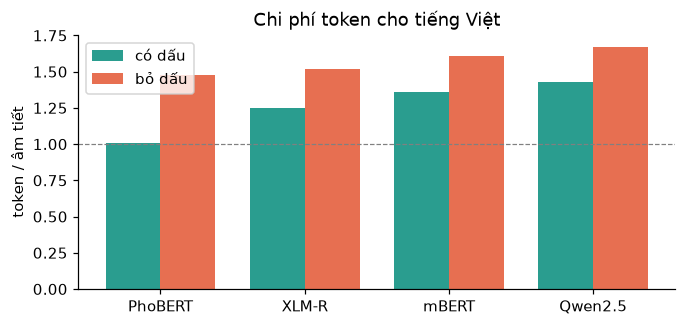

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(bang_tk)); w = 0.38
ax.bar(x - w / 2, bang_tk["token / âm tiết (có dấu)"], w, label="có dấu", color="#2a9d8f")
ax.bar(x + w / 2, bang_tk["token / âm tiết (bỏ dấu)"], w, label="bỏ dấu", color="#e76f51")
ax.set_xticks(x); ax.set_xticklabels([t.split(" (")[0] for t in bang_tk["tokenizer"]])
ax.axhline(1, color="gray", ls="--", lw=.8); ax.set_ylabel("token / âm tiết"); ax.legend(); ax.set_title("Chi phí token cho tiếng Việt")
plt.show()

**Đọc kết quả:**

- Mô hình **được huấn luyện chủ yếu trên tiếng Việt** (PhoBERT) cần ít token nhất, vì từ vựng chứa sẵn các từ ghép.
- Tokenizer **đa ngôn ngữ** (XLM-R ≈1,25; mBERT ≈1,36) có từ điển chia cho hàng trăm ngôn ngữ nên tiếng Việt tốn nhiều token hơn; Qwen cấp byte tốn nhất (≈1,43), một phần vì dấu tiếng Việt (nhiều byte UTF-8) phải được học gộp.
- **Bỏ dấu làm số token tăng ở mọi tokenizer** (khoảng +17% đến +46%; mạnh nhất ở PhoBERT), vì chuỗi không dấu hiếm gặp trong dữ liệu huấn luyện nên bị cắt vụn. Một lý do nữa để *đừng bỏ dấu* khi dùng mô hình tiền huấn luyện (ngược với kết quả của mô hình TF-IDF ở Bài 3, vốn học từ đầu trên chính dữ liệu của ta).
- Với API tính tiền theo token, tiếng Việt thường đắt hơn tiếng Anh cho cùng nội dung.

Token của Qwen trông như "mã hóa lỗi" (`Ãºng`) vì nó là byte UTF-8 hiển thị dưới dạng ký tự ánh xạ; ghép lại và `decode` vẫn đúng:

In [10]:
qk = tks["Qwen2.5 (BPE cấp byte)"][0]
ids = qk("Chúng tôi rất hài lòng")["input_ids"]
print("token thô :", qk.convert_ids_to_tokens(ids))
print("từng token:", [qk.decode([i]) for i in ids])
print("ghép lại  :", qk.decode(ids))

token thô : ['Ch', 'Ãºng', 'ĠtÃ´i', 'Ġráº¥t', 'ĠhÃłi', 'ĠlÃ²ng']
từng token: ['Ch', 'úng', ' tôi', ' rất', ' hài', ' lòng']
ghép lại  : Chúng tôi rất hài lòng


Mảnh "Chú" bị cắt giữa ký tự (`Ch` + byte của `ú`): vì thế khi giải mã *từng token riêng lẻ*, bạn có thể thấy ký tự lỗi `�`. Đó là hệ quả của BPE cấp byte, không phải lỗi.

## 5. Tải mô hình và đọc đầu ra

`AutoModel` trả về **biểu diễn theo ngữ cảnh** của từng token: tensor `last_hidden_state` cỡ `(batch, độ dài, 768)`.

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModel.from_pretrained("vinai/phobert-base").to(device).eval()
print(f"Số tham số: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} triệu | lớp: {model.config.num_hidden_layers} | chiều ẩn: {model.config.hidden_size} | vị trí tối đa: {model.config.max_position_embeddings}")

@torch.no_grad()
def ma_hoa(cau, layer=-1):
    enc = tok(cau, return_tensors="pt", truncation=True, max_length=256).to(device)
    out = model(**enc, output_hidden_states=True)
    return enc, out.hidden_states[layer][0].cpu()                      # (số token, 768)

enc, H = ma_hoa(segment("Sản phẩm này rất tốt ."))
print("hidden_states[-1]:", tuple(H.shape), "→ mỗi token một vector 768 chiều")

Số tham số: 135 triệu | lớp: 12 | chiều ẩn: 768 | vị trí tối đa: 258


hidden_states[-1]: (7, 768) → mỗi token một vector 768 chiều


### 5.1 Vector câu: gộp trung bình có mặt nạ

Muốn một vector cho **cả câu**, ta gộp các vector token. Cách phổ biến: **trung bình** (bỏ qua ô đệm). Dùng làm đặc trưng cho phân loại hoặc tìm kiếm (Bài 12).

In [12]:
@torch.no_grad()
def vec_cau(texts, bs=32):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok([segment(t) for t in texts[i:i + bs]], return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
        h = model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu())
    return torch.cat(out).numpy()

cau = ["Giao hàng nhanh, đóng gói cẩn thận.", "Vận chuyển mau lẹ, gói hàng chắc chắn.", "Ứng dụng hay treo, rất thất vọng."]
E = vec_cau(cau)
En = E / np.linalg.norm(E, axis=1, keepdims=True)
print(pd.DataFrame(En @ En.T, index=["nhanh/cẩn thận", "mau lẹ/chắc chắn", "treo/thất vọng"], columns=["nhanh/cẩn thận", "mau lẹ/chắc chắn", "treo/thất vọng"]).round(2).to_string())

                  nhanh/cẩn thận  mau lẹ/chắc chắn  treo/thất vọng
nhanh/cẩn thận              1.00              0.75            0.55
mau lẹ/chắc chắn            0.75              1.00            0.58
treo/thất vọng              0.55              0.58            1.00


So sánh với Bài 2: hai câu **cùng nghĩa nhưng khác chữ** ("giao hàng nhanh" / "vận chuyển mau lẹ") giờ có cosine cao hơn nhiều so với câu khác chủ đề — điều TF-IDF không làm được. Lưu ý: PhoBERT chưa được tinh chỉnh để so khớp câu; cosine của nó thường nằm trong một dải hẹp (ở đây ≈0,55 đến ≈0,75), nên chênh lệch nhỏ chưa đủ tin cậy để xếp hạng. Mô hình *embedding chuyên dụng* ở Bài 12 được huấn luyện để phân tách tốt hơn.

## 6. Embedding theo ngữ cảnh: một từ, nhiều nghĩa

Ở Bài 5 ta thấy embedding tĩnh gán **một** vector cho mỗi từ. Với "đá" (cú đá / hòn đá / nước đá) đó là vấn đề. Mô hình theo ngữ cảnh tạo **vector khác nhau cho mỗi lần xuất hiện**:

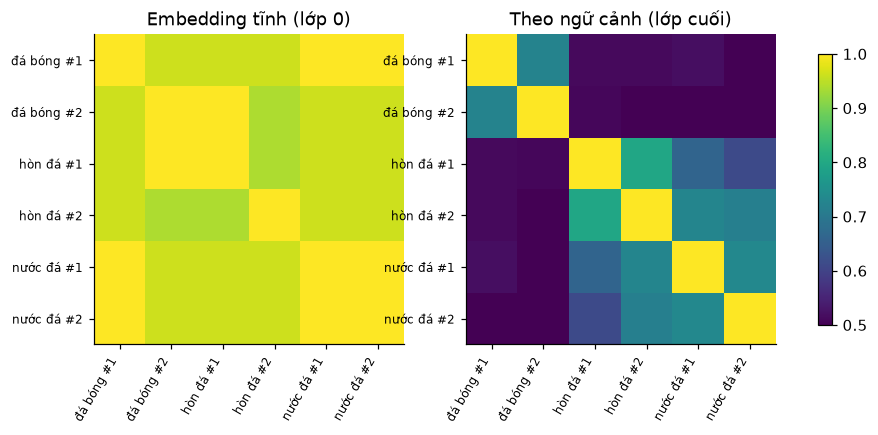

lớp 0 (embedding tĩnh)    : cosine TB cùng nghĩa = 0.97 | khác nghĩa = 0.97 | chênh = -0.00
lớp cuối (theo ngữ cảnh)  : cosine TB cùng nghĩa = 0.75 | khác nghĩa = 0.56 | chênh = +0.19


In [13]:
ngu_canh = [
    ("đá bóng",  "Anh_ấy đá quả_bóng vào lưới ."),
    ("đá bóng",  "Cầu_thủ đá phạt rất đẹp ."),
    ("hòn đá",   "Hòn đá này rất nặng ."),
    ("hòn đá",   "Anh nhặt viên đá ven đường ."),
    ("nước đá",  "Cho thêm đá vào ly nước ."),
    ("nước đá",  "Ly trà đá mát lạnh ."),
]

@torch.no_grad()
def vec_tu(cau, tu="đá", layer=-1):
    enc = tok(cau, return_tensors="pt").to(device)
    toks = tok.convert_ids_to_tokens(enc["input_ids"][0])
    idx = toks.index(tu)
    hs = model(**enc, output_hidden_states=True).hidden_states[layer][0, idx].cpu().numpy()
    return hs / np.linalg.norm(hs)

V_ctx = np.array([vec_tu(c) for _, c in ngu_canh])
V_emb = np.array([vec_tu(c, layer=0) for _, c in ngu_canh])         # lớp 0 = embedding tĩnh (chưa có ngữ cảnh)
nhan = [f"{n} #{i % 2 + 1}" for i, (n, _) in enumerate(ngu_canh)]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, M, ten in [(ax[0], V_emb @ V_emb.T, "Embedding tĩnh (lớp 0)"), (ax[1], V_ctx @ V_ctx.T, "Theo ngữ cảnh (lớp cuối)")]:
    im = a.imshow(M, vmin=0.5, vmax=1, cmap="viridis")
    a.set_xticks(range(6)); a.set_xticklabels(nhan, rotation=60, ha="right", fontsize=8)
    a.set_yticks(range(6)); a.set_yticklabels(nhan, fontsize=8); a.set_title(ten)
plt.colorbar(im, ax=ax, shrink=.8); plt.show()

def tb_cos(M):
    cung = np.mean([M[i, j] for i, j in [(0, 1), (2, 3), (4, 5)]])
    khac = np.mean([M[i, j] for i in range(6) for j in range(6) if i // 2 != j // 2])
    return cung, khac

for ten, M in [("lớp 0 (embedding tĩnh)", V_emb @ V_emb.T), ("lớp cuối (theo ngữ cảnh)", V_ctx @ V_ctx.T)]:
    c, k = tb_cos(M)
    print(f"{ten:26s}: cosine TB cùng nghĩa = {c:.2f} | khác nghĩa = {k:.2f} | chênh = {c - k:+.2f}")

**Đọc hình và số liệu:** ở lớp embedding tĩnh (trái), cả 6 lần xuất hiện của "đá" có vector **gần như y hệt nhau** (cosine TB ≈ 0,97; không hoàn toàn bằng 1 vì lớp này còn cộng vector vị trí) và **không phân biệt nghĩa**: cùng nghĩa hay khác nghĩa đều ≈ 0,97. Ở lớp cuối (phải), vector của "đá" **đã phụ thuộc vào câu**: hai lần dùng cùng nghĩa có cosine ≈ 0,75, cao hơn hẳn các nghĩa khác nhau (≈ 0,56). Đây là khác biệt cốt lõi giữa embedding tĩnh (Word2Vec) và biểu diễn theo ngữ cảnh (BERT/PhoBERT), và là lý do chính khiến mô hình kiểu BERT mạnh hơn nhiều.

## 7. Đằng sau `pipeline`

`pipeline("fill-mask")` gói ba bước: **tokenizer → mô hình → hậu xử lý**. Ta thử cả hai: dùng `pipeline`, rồi tự làm lại để thấy không có phép màu nào.

In [14]:
from transformers import pipeline

fm = pipeline("fill-mask", model="vinai/phobert-base", tokenizer="vinai/phobert-base", device=0 if device == "cuda" else -1)
for cau in ["Hà_Nội là thủ_đô của <mask> .", "Sản_phẩm này <mask> quá , tôi rất hài_lòng ."]:
    print(cau)
    for r in fm(cau, top_k=4):
        print(f"    {r['token_str']:12s} {r['score']:.3f}")

Hà_Nội là thủ_đô của <mask> .
    Việt_Nam     0.837
    hoà_bình     0.036
    đất_nước     0.031
    thế_giới     0.012
Sản_phẩm này <mask> quá , tôi rất hài_lòng .
    tốt          0.398
    đẹp          0.113
    rẻ           0.062
    hay          0.030


In [15]:
# Tự làm lại: tokenizer -> mô hình -> lấy logits tại vị trí <mask> -> softmax -> top-k
mlm = AutoModelForMaskedLM.from_pretrained("vinai/phobert-base").to(device).eval()
cau = "Hà_Nội là thủ_đô của <mask> ."
enc = tok(cau, return_tensors="pt").to(device)
vi_tri = (enc["input_ids"][0] == tok.mask_token_id).nonzero().item()
with torch.no_grad():
    logits = mlm(**enc).logits[0, vi_tri]
p = logits.softmax(-1)
top = p.topk(4)
print([(tok.convert_ids_to_tokens(int(i)), round(float(v), 3)) for v, i in zip(top.values, top.indices)])

[('Việt_Nam', 0.837), ('hoà_bình', 0.036), ('đất_nước', 0.031), ('thế_giới', 0.012)]


Kết quả trùng với `pipeline`. Trong thực tế, pipeline hữu ích để thử nhanh; còn khi cần kiểm soát (batch, độ dài, GPU, hậu xử lý riêng) ta tự gọi tokenizer + mô hình như trên — và đó chính là điều ta sẽ làm khi tinh chỉnh ở Bài 10.

Nhận xét thêm: dự đoán "Việt_Nam" với xác suất rất cao là *tri thức* mô hình học được khi tiền huấn luyện trên Wikipedia và tin tức tiếng Việt. Điều này cũng có nghĩa mô hình mang theo **thiên kiến và lỗi** của dữ liệu đó (Bài 14).

## 8. Tổng kết

- Hugging Face: Hub + `transformers` + `datasets` + `tokenizers`. **Kiểm tra giấy phép** trước khi dùng.
- Tokenizer subword (BPE/WordPiece/Unigram) loại bỏ OOV; PhoBERT cần **văn bản đã tách từ**; giới hạn 256 token.
- Tokenizer ảnh hưởng chi phí: mô hình đa ngôn ngữ và cấp byte tốn nhiều token hơn cho tiếng Việt; **bỏ dấu làm tăng mạnh số token**.
- `last_hidden_state` cho vector theo ngữ cảnh mỗi token; gộp trung bình (có mặt nạ) cho vector câu.
- Embedding theo ngữ cảnh giải quyết đa nghĩa — hạn chế lớn của Word2Vec.

## Bài tập

1. **(Dễ)** Dùng `bpe_train` với 20, 120 và 400 phép gộp. Vẽ số token trung bình trên mỗi âm tiết của tập valid theo số phép gộp. Có điểm bão hòa không?
2. **(Dễ)** Tokenize cùng một câu **có và không có** tách từ bằng PhoBERT. Số token khác nhau bao nhiêu? Vector câu có khác nhau nhiều không (cosine)?
3. **(Vừa)** Đo cosine giữa vector "đá" khi dùng `layer=4`, `8`, `12`. Lớp nào tách các nghĩa tốt nhất? Giải thích.
4. **(Vừa)** Dùng vector câu PhoBERT (trung bình) + Logistic Regression để phân loại cảm xúc trên `reviews_vi.csv`. So với TF-IDF của Bài 3. (Không tinh chỉnh mô hình!)
5. **(Khó)** Cài **WordPiece** (chọn cặp theo $\frac{\text{count}(ab)}{\text{count}(a)\,\text{count}(b)}$ thay vì tần suất thô) và so các phép gộp đầu tiên với BPE.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Số token/âm tiết giảm nhanh ở ~100 phép gộp đầu rồi chậm dần, đến mức tiệm cận 1 (một âm tiết = một token) khi hầu hết âm tiết phổ biến đã thành một mảnh.
2. Không tách từ: các từ ghép thành các âm tiết rời → nhiều token hơn; cosine thường vẫn cao nhưng không bằng 1.
3. Các lớp giữa/cao thường mang nghĩa ngữ cảnh nhiều nhất; lớp thấp gần embedding tĩnh (ít phân biệt nghĩa).
4. Đặc trưng PhoBERT đóng băng thường cho kết quả tốt trên dữ liệu thật, nhưng trên kho tổng hợp này TF-IDF vốn đã mạnh; so sánh qua nhiều seed và trên câu khó.
5. WordPiece ưu tiên cặp có "gắn kết" cao (PMI) thay vì chỉ phổ biến; vài phép gộp đầu sẽ khác BPE.
</details>

**Tiếp theo → Bài 10:** tinh chỉnh PhoBERT cho phân loại cảm xúc — trên dữ liệu thật.

**Đọc thêm:** [HF NLP Course (vi), Chương 2: Sử dụng 🤗 Transformers](https://huggingface.co/docs/course/vi/chapter2/1) · [HF NLP Course (vi), Chương 6: Thư viện Tokenizers](https://huggingface.co/docs/course/vi/chapter6/1) · Sennrich và cộng sự, *Neural Machine Translation of Rare Words with Subword Units* (2016)